# 04 — POMDP + belief state, visually

<div><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#A3A01B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">BELIEF</span><span style="display:inline-block;background:#8C564B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">HISTORY</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span></div>

Now the world contains a fact you cannot directly see: **is the Sword actually active?**

Instead, you get a noisy clue: `glint` or `no glint`.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-040" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Partial observability</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDDEN SWORD STATE</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-040)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">NOISY SENSOR</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-040)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-040)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF</text>
</svg>
</div>


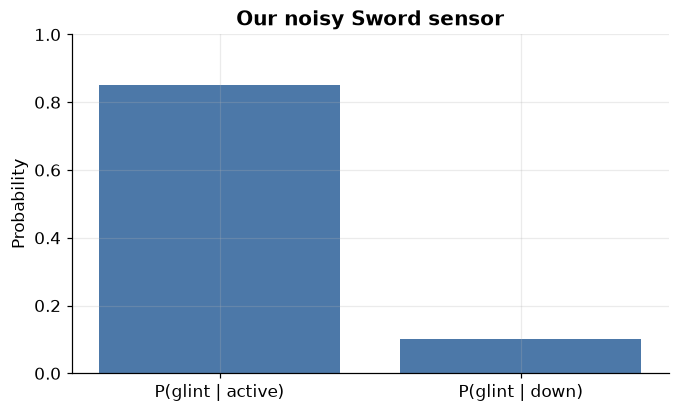

In [1]:
from pathlib import Path
import sys, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import COLORS

P_GLINT_IF_ACTIVE = 0.85
P_GLINT_IF_DOWN = 0.10

plt.figure(figsize=(7,4))
plt.bar(["P(glint | active)","P(glint | down)"], [P_GLINT_IF_ACTIVE, P_GLINT_IF_DOWN], color=COLORS["STATE"])
plt.ylim(0,1)
plt.ylabel("Probability")
plt.title("Our noisy Sword sensor")
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. Observation is evidence, not truth</div></div>

A `glint` makes Sword-active more likely, but does not prove it.

A belief state represents uncertainty over possible hidden states.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-042" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Belief update</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PRIOR BELIEF</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-042)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-042)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BAYES UPDATE</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-042)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POSTERIOR BELIEF</text>
</svg>
</div>


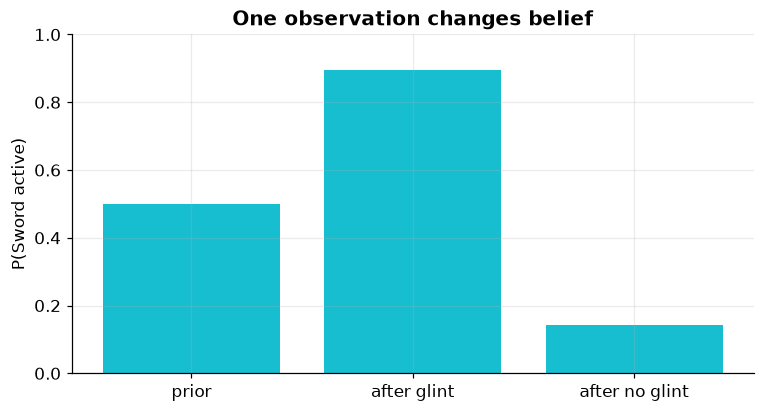

In [2]:
def bayes_update(prior_active, glint):
    if glint:
        la, ld = P_GLINT_IF_ACTIVE, P_GLINT_IF_DOWN
    else:
        la, ld = 1-P_GLINT_IF_ACTIVE, 1-P_GLINT_IF_DOWN
    num = la * prior_active
    return num / (num + ld*(1-prior_active))

prior = 0.5
post_glint = bayes_update(prior, True)
post_no = bayes_update(prior, False)

plt.figure(figsize=(8,4))
plt.bar(["prior","after glint","after no glint"], [prior, post_glint, post_no], color=COLORS["OBSERVATION"])
plt.ylim(0,1)
plt.ylabel("P(Sword active)")
plt.title("One observation changes belief")
plt.show()

<div style="border-left:10px solid #8C564B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#8C564B">HISTORY</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. History accumulates evidence</div></div>

One noisy observation can be wrong.

A sequence of observations can make your belief more confident.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-044" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">History → belief</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">o₁</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-044)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">o₂</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-044)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">o₃</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-044)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">o₄</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-044)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF AFTER HISTORY</text>
</svg>
</div>


,t,glint,P_active
0,0,True,0.894737
1,1,True,0.986348
2,2,True,0.998374
3,3,True,0.999808
4,4,True,0.999977
5,5,True,0.999997
6,6,False,0.999984
7,7,True,0.999998
8,8,True,1.000000
9,9,True,1.000000


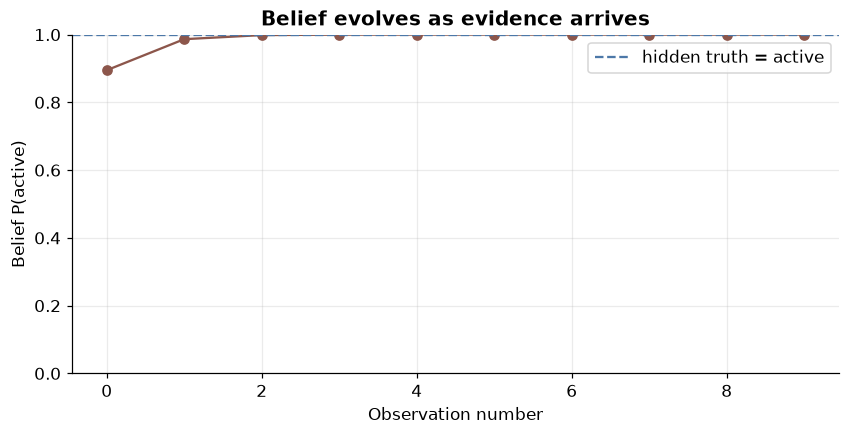

In [3]:
rng = random.Random(4)
true_active = True
belief = 0.5
rows = []

for t in range(10):
    p = P_GLINT_IF_ACTIVE if true_active else P_GLINT_IF_DOWN
    glint = rng.random() < p
    belief = bayes_update(belief, glint)
    rows.append((t, glint, belief))

df = pd.DataFrame(rows, columns=["t","glint","P_active"])
display(df)

plt.figure(figsize=(9,4))
plt.plot(df["t"], df["P_active"], marker="o", color=COLORS["HISTORY"])
plt.axhline(1.0, linestyle="--", label="hidden truth = active")
plt.ylim(0,1)
plt.xlabel("Observation number")
plt.ylabel("Belief P(active)")
plt.title("Belief evolves as evidence arrives")
plt.legend()
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. Latest observation can be insufficient</div></div>

Suppose the newest clue is `no glint`.

If the previous nine clues strongly favored Sword-active, your belief may still say active is very likely.

So `latest observation` and `state for decision-making` are not necessarily the same thing.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-046" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Why memory matters</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LATEST OBS ONLY</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-046)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LOSE HISTORY</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-046)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">AMBIGUOUS</text>
</svg>
</div>


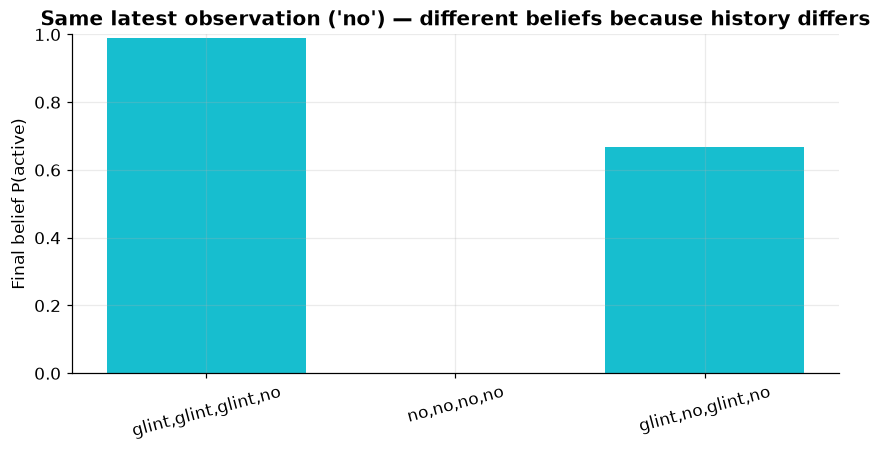

In [4]:
histories = {
    "glint,glint,glint,no": [True,True,True,False],
    "no,no,no,no": [False,False,False,False],
    "glint,no,glint,no": [True,False,True,False],
}
finals = []

for name, hist in histories.items():
    b = 0.5
    for o in hist:
        b = bayes_update(b, o)
    finals.append(b)

plt.figure(figsize=(9,4))
plt.bar(histories.keys(), finals, color=COLORS["OBSERVATION"])
plt.ylim(0,1)
plt.ylabel("Final belief P(active)")
plt.xticks(rotation=15)
plt.title("Same latest observation ('no') — different beliefs because history differs")
plt.show()

<div style="border-left:10px solid #A3A01B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#A3A01B">BELIEF</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. A policy can act on belief</div></div>

Instead of choosing from hidden truth, the policy chooses from its current belief.

Example:

- if `P(active) > 0.7`, avoid body attack
- otherwise, risk direct body damage

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-048" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Belief can be decision state</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF P(active)</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-048)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY THRESHOLD</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-048)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAFE / RISKY ACTION</text>
</svg>
</div>


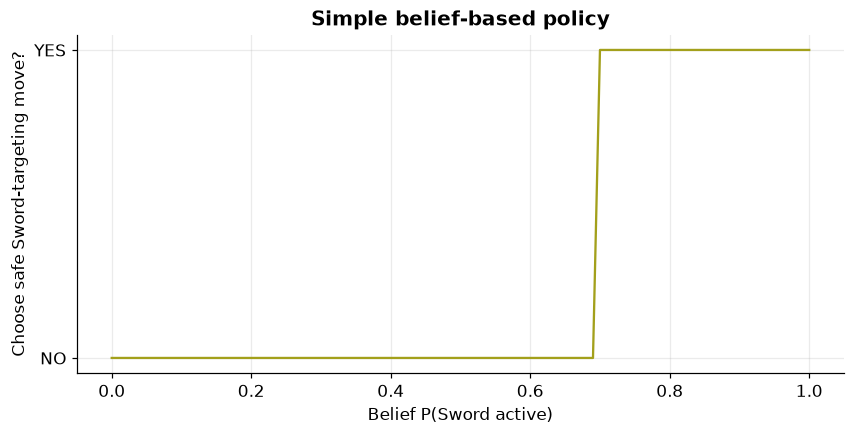

In [5]:
beliefs = np.linspace(0,1,101)
safe = (beliefs > 0.7).astype(int)

plt.figure(figsize=(9,4))
plt.plot(beliefs, safe, color=COLORS["BELIEF"])
plt.xlabel("Belief P(Sword active)")
plt.ylabel("Choose safe Sword-targeting move?")
plt.yticks([0,1], ["NO","YES"])
plt.title("Simple belief-based policy")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">5. Map this to LifeOS</div></div>

Hidden state can include facts you do not directly observe yet: someone's intent, an external approval, an unresolved dependency, or the user's current objective.

Telemetry gives evidence. History changes your internal estimate.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0410" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">LifeOS as partial observability</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HIDDEN WORLD</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0410)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SCREEN / EMAIL / HISTORY</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0410)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF / INTERNAL STATE</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0410)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
</svg>
</div>


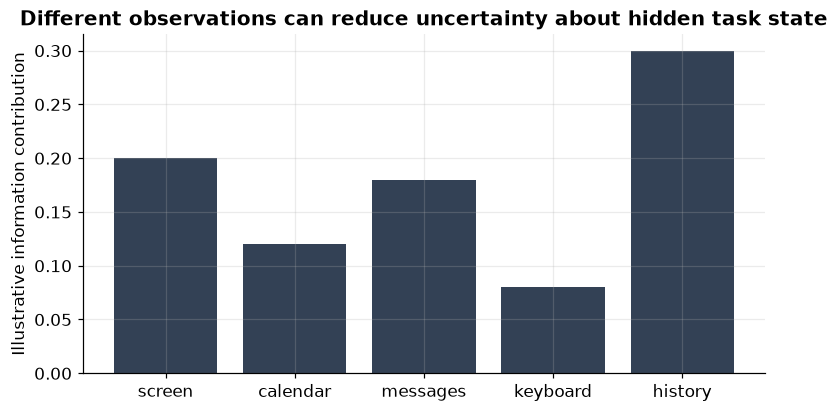

In [6]:
sources = ["screen","calendar","messages","keyboard","history"]
uncertainty_reduction = [0.20,0.12,0.18,0.08,0.30]

plt.figure(figsize=(8,4))
plt.bar(sources, uncertainty_reduction, color=COLORS["ENVIRONMENT"])
plt.ylabel("Illustrative information contribution")
plt.title("Different observations can reduce uncertainty about hidden task state")
plt.show()

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">KEY IDEA</div><div style="font-size:21px;font-weight:800;margin-top:4px">Memorize</div></div>

**Observation = what I saw. History = what I've seen/done. Belief = what I think the hidden world probably is given that history.**

Next: neural-network weights.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-0412" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">POMDP mental model</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">OBSERVATION</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0412)"/>
<rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HISTORY</text>
<line x1="405.0" y1="82" x2="467.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0412)"/>
<rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="#A3A01B" stroke="#A3A01B" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BELIEF</text>
<line x1="630.0" y1="82" x2="692.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-0412)"/>
<rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
</svg>
</div>
